<a href="https://colab.research.google.com/github/LuckyMayHedgehog/Machine-Learning-data-science/blob/main/02-eda-imbalanced-insurance/eda_imbalanced_insurance.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [ ]:
!pip install kagglehub --quiet

path = kagglehub.dataset_download("arashnic/imbalanced-data-practice")
print("Шлях до датасету:", path)

print("Файли:", os.listdir(path))

file_path = os.path.join(path, "aug_train.csv")
df = pd.read_csv(file_path)

print(f"Розмірність: {df.shape}")
df.head()

100%|██████████| 6.68M/6.68M [00:00<00:00, 158MB/s]

Extracting files...


Шлях до датасету: /root/.cache/kagglehub/datasets/arashnic/imbalanced-data-practice/versions/4
Файли: ['aug_train.csv', 'aug_test.csv', 'sample_submission.csv']
Розмірність: (382154, 12)


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,167647,Male,22,1,7.0,1,< 1 Year,No,2630.0,152.0,16,0
1,17163,Male,42,1,28.0,0,1-2 Year,Yes,43327.0,26.0,135,0
2,32023,Female,66,1,33.0,0,1-2 Year,Yes,35841.0,124.0,253,0
3,87447,Female,22,1,33.0,0,< 1 Year,No,27645.0,152.0,69,0
4,501933,Male,28,1,46.0,1,< 1 Year,No,29023.0,152.0,211,0


In [ ]:
print("INFO:")
df.info()

print("\nNanS:")
missing_data = df.isnull().sum()
print(missing_data[missing_data > 0])

print("\nDescription:")
display(df.describe().T)

print("\nРозподіл 'Response'")
counts = df["Response"].value_counts()
percent = df["Response"].value_counts(normalize=True) * 100

balance_df = pd.DataFrame({"Кількість": counts, "Відсоток (%)": percent})
display(balance_df)

INFO:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 382154 entries, 0 to 382153
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    382154 non-null  int64  
 1   Gender                382154 non-null  object 
 2   Age                   382154 non-null  int64  
 3   Driving_License       382154 non-null  int64  
 4   Region_Code           382154 non-null  float64
 5   Previously_Insured    382154 non-null  int64  
 6   Vehicle_Age           382154 non-null  object 
 7   Vehicle_Damage        382154 non-null  object 
 8   Annual_Premium        382154 non-null  float64
 9   Policy_Sales_Channel  382154 non-null  float64
 10  Vintage               382154 non-null  int64  
 11  Response              382154 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 35.0+ MB

NanS:
Series([], dtype: int64)

Description:


,count,mean,std,min,25%,50%,75%,max
id,382154.0,234392.953477,139527.487326,1.0,115006.25,230461.5,345434.75,508145.0
Age,382154.0,38.545691,15.226897,20.0,25.00,36.0,49.00,85.0
Driving_License,382154.0,0.998108,0.043455,0.0,1.00,1.0,1.00,1.0
Region_Code,382154.0,26.406867,13.181241,0.0,15.00,28.0,35.00,52.0
Previously_Insured,382154.0,0.489182,0.499884,0.0,0.00,0.0,1.00,1.0
Annual_Premium,382154.0,30711.271362,17061.595532,2630.0,24546.00,31692.0,39447.75,540165.0
Policy_Sales_Channel,382154.0,111.939812,54.286511,1.0,26.00,145.0,152.00,163.0
Vintage,382154.0,154.189429,83.735107,10.0,81.00,154.0,227.00,299.0
Response,382154.0,0.163811,0.370104,0.0,0.00,0.0,0.00,1.0



Розподіл 'Response'


,Кількість,Відсоток (%)
Response,,
0,319553,83.618908
1,62601,16.381092


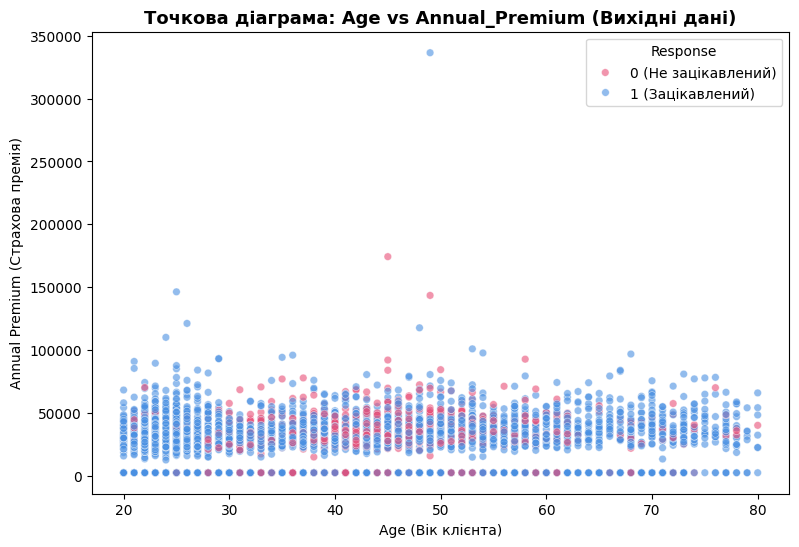

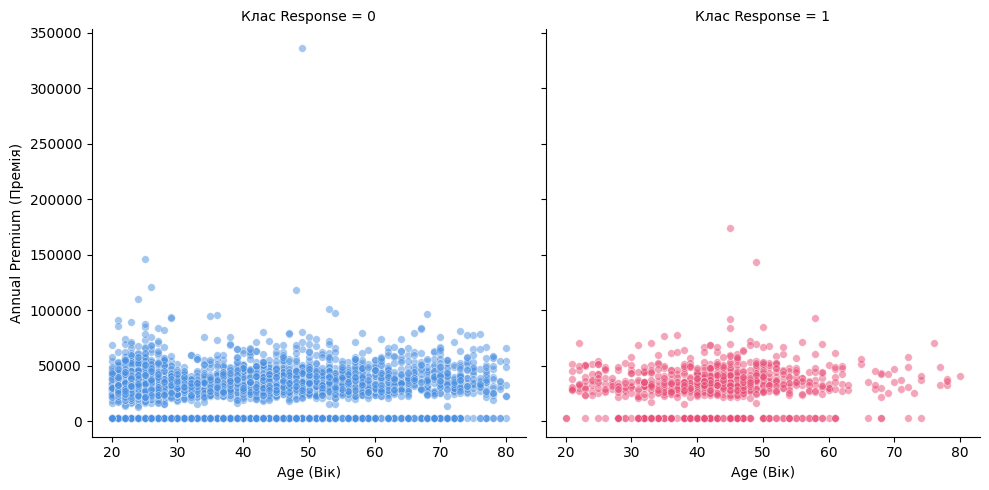

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Беремо підвибірку для швидкого та чіткого рендерингу точок
df_sample = df.sample(n=5000, random_state=42)

# 1. Загальний точковий графік
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df_sample,
    x="Age",
    y="Annual_Premium",
    hue="Response",
    palette=["#4a90e2", "#e94e77"],
    alpha=0.6,
    s=30,
)
plt.title(
    "Точкова діаграма: Age vs Annual_Premium (Вихідні дані)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Age (Вік клієнта)")
plt.ylabel("Annual Premium (Страхова премія)")
plt.legend(title="Response", labels=["0 (Не зацікавлений)", "1 (Зацікавлений)"])
plt.show()

# 2. Роздільні точкові діаграми за класами
g = sns.FacetGrid(
    df_sample,
    col="Response",
    hue="Response",
    palette=["#4a90e2", "#e94e77"],
    height=5,
)
g.map(
    sns.scatterplot,
    "Age",
    "Annual_Premium",
    alpha=0.5,
    s=30,
)
g.set_axis_labels("Age (Вік)", "Annual Premium (Премія)")
g.set_titles(col_template="Клас Response = {col_name}")
plt.show()

SMOTE (Synthetic Minority Over-sampling Technique): Для кожного зразка $x_i$ рідкісного класу знаходить $k$ найближчих сусідів (за замовчуванням $k=5$) з того самого класу.
Обирає випадкового сусіда $x_{zi}$ і створює нову синтетичну точку вздовж відрізка між ними.
Генерує однакову пропорцію зразків для всіх точок меншості без урахування складності області.


ADASYN (Adaptive Synthetic):
Працює схоже на SMOTE, але використовує адаптивний розподіл ваг.
Для кожного об'єкта міноритарного класу оцінює частку сусідів з мажоритарного класу.
Якщо точка оточена здебільшого представниками протилежного класу (тобто лежить прямо на межі рішень, де класифікувати найважче), їй присвоюється вища вага і біля неї генерується значно більше синтетичних точок. Якщо точка знаходиться глибоко у своєму класі, біля неї генерується мінімум екземплярів.

Приклад:



Маємо 10 000 транзакцій:

9 900 - нормальні 100 - шахрайські

imbalanced dataset  

majority class - клас більшості - Normal

minority class - клас меншості - Fraud

9900 / 10000 = 99%

Accuracy = 99%, АЛЕ 100 шахрайських - не знайшла жодного



OVER-SAMPLING - ми збільшуємо кількість прикладів minority class.  

Тепер модель під час навчання бачить обидва класи приблизно однаково часто.

Але питання - звідки взяти ще 900 "поганих, шахрайських прикладів"?

RandomOverSampler - Візьми існуючі minority samples і просто повтори їх ("ABCDACCB") - random over-sampling робить sampling with replacement - вибірку з повторенням  



АЛЕ: Точки просто накладаються одна на одну, модель думає - кожен конкретний приклад дуже важливий, Але нової інформації не з'явилося..





ТОМУ:

SMOTE - Synthetic Minority Over-sampling Technique

техніка створення синтетичних прикладів minority class.

Він не копіює, Він створює нову точку між існуючими точками.



НАПРИКЛАД:

У нас є два minority samples:

A = (2, 4)

B = (6, 8)

SMOTE: A ------- X ------ B

X = (4, 6)

Як SMOTE знає, де створювати точку? - nearest neighbors  





ADASYN:

Adaptive Synthetic Sampling

Як i SMOTE: знаходить сусідів; створює synthetic samples; використовує interpolation.



Але SMOTE іноді не розуміє:

У деякій області minority samples знаходяться далеко від majority: легка область для класифікації.



А в іншій області класи перемішані: це складна область. Легка помилка.

ADASYN - Дивиться, де модель має проблеми і створює там більше minority samples. Він адаптивний. Чим більше в околиці неправильних / чужих класів, тим більше synthetic samples ADASYN генерує.

Документація прямо зазначає, що SMOTE може з'єднати inliers та outliers, а ADASYN може сфокусуватися на outliers.









In [ ]:
from imblearn.over_sampling import ADASYN, SMOTE

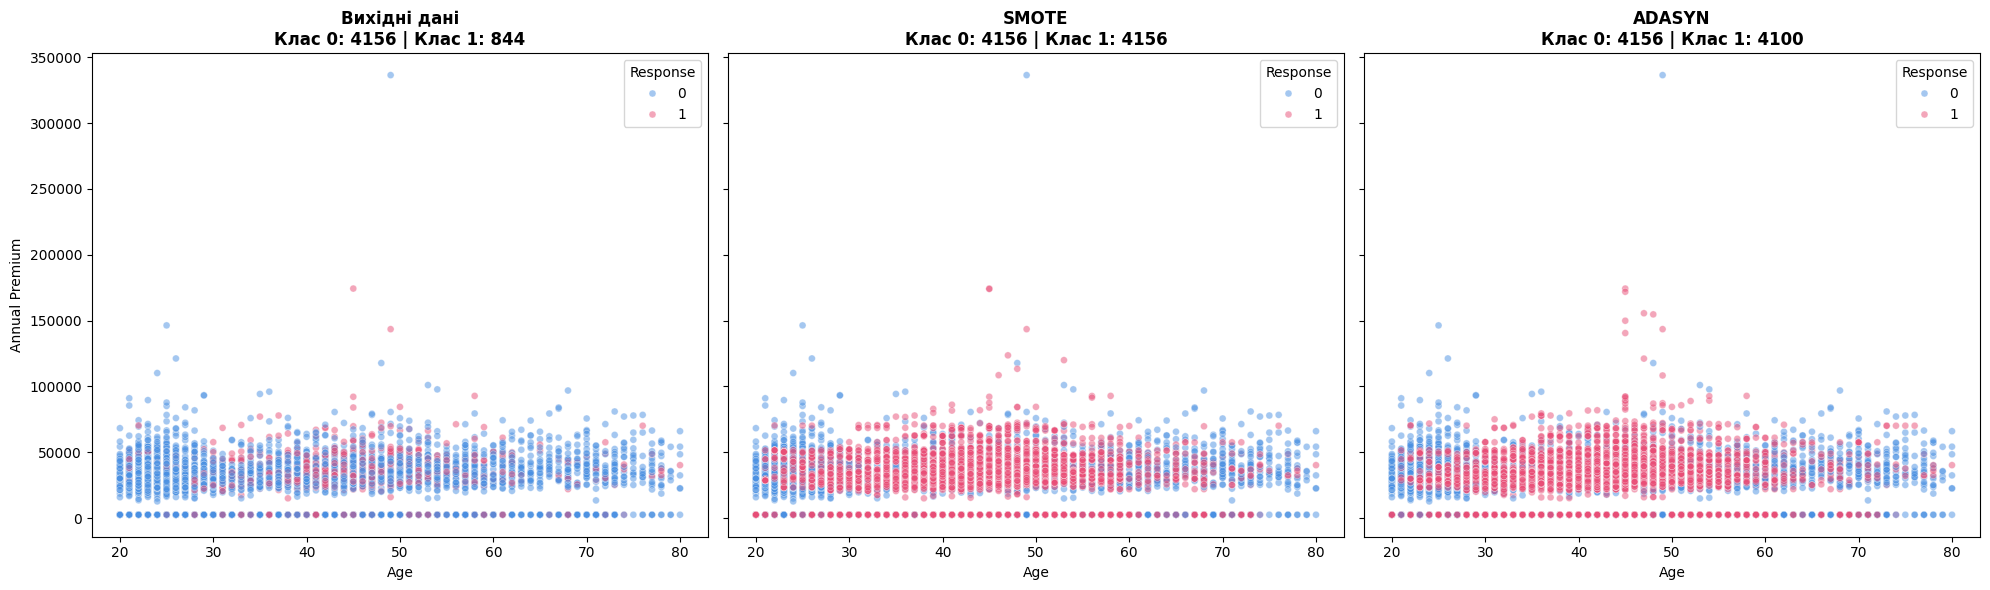

In [ ]:

sample_size = 5000
df_resample = df.sample(n=sample_size, random_state=42) #зерно випадковості, щоб не кожен раз різне

features = ["Age", "Annual_Premium"]
X = df_resample[features]
y = df_resample["Response"]
#X - age, annual_premium, y - response(0/1)


# 2. Застосування SMOTE
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X, y)

# 3. Застосування ADASYN
adasyn = ADASYN(random_state=42)
X_adasyn, y_adasyn = adasyn.fit_resample(X, y)

# 4. Порівняльна візуалізація
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
palette = ["#4a90e2", "#e94e77"]

# Графік 1: До балансування
sns.scatterplot(
    ax=axes[0],
    x=X["Age"],
    y=X["Annual_Premium"],
    hue=y,
    palette=palette,
    alpha=0.5,
    s=25,
)
axes[0].set_title(
    f"Вихідні дані\nКлас 0: {sum(y == 0)} | Клас 1: {sum(y == 1)}",
    fontsize=12,
    fontweight="bold",
)
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Annual Premium")

# Графік 2: Після SMOTE
sns.scatterplot(
    ax=axes[1],
    x=X_smote["Age"],
    y=X_smote["Annual_Premium"],
    hue=y_smote,
    palette=palette,
    alpha=0.5,
    s=25,
)
axes[1].set_title(
    f"SMOTE\nКлас 0: {sum(y_smote == 0)} | Клас 1: {sum(y_smote == 1)}",
    fontsize=12,
    fontweight="bold",
)
axes[1].set_xlabel("Age")

# Графік 3: Після ADASYN
sns.scatterplot(
    ax=axes[2],
    x=X_adasyn["Age"],
    y=X_adasyn["Annual_Premium"],
    hue=y_adasyn,
    palette=palette,
    alpha=0.5,
    s=25,
)
axes[2].set_title(
    f"ADASYN\nКлас 0: {sum(y_adasyn == 0)} | Клас 1: {sum(y_adasyn == 1)}",
    fontsize=12,
    fontweight="bold",
)
axes[2].set_xlabel("Age")

plt.tight_layout()
plt.show()

дані сильно незбалансовані: класу 0 приблизно в 5 разів більше, ніж класу 1.

SMOTE повністю збалансував класи на 2 фото - 4156, 4156
SMOTE створив додаткові 3312 синтетичних об'єктів класу 1. На графіку тому стало набагато більше рожевих точок. Причому важливо: ці додаткові рожеві точки -  не прості копії старих клієнтів. SMOTE створив нові значення Age та Annual_Premium, орієнтуючись на сусідні об'єкти класу 1.

ADASYN - 4156, 4100

ADASYN теж дуже сильно збалансував класи, але не зробив їх абсолютно однаковими.

SMOTE створює синтетичні точки, орієнтуючись на сусідні об'єкти класу 1. Тому після нього рожеві точки досить рівномірно заповнюють області, де вже були представники класу 1.



ADASYN більше концентрує нові точки в областях, де класи сильніше перемішані й де класифікація є складнішою.



Тому на третьому графіку можна побачити більше рожевих точок у деяких областях, де поруч знаходяться сині точки.

